# Credit Wise Loan Approval System


In [152]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score,f1_score,confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

In [97]:
df = pd.read_csv("loan approval data.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    str    
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    str    
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    str    
 15  Property_Area       950 non-null    str    
 16  Education_Level   

In [98]:
categorical_col = df.select_dtypes(include = ["str"]).columns
numerical_col = df.select_dtypes(include = ["number"]).columns

In [99]:
num_imp = SimpleImputer(strategy = "mean")
df[numerical_col] = num_imp.fit_transform(df[numerical_col])
col_imp = SimpleImputer(strategy = "most_frequent")
df[categorical_col] = col_imp.fit_transform(df[categorical_col])

# EDA- Exploratory Data Analysis

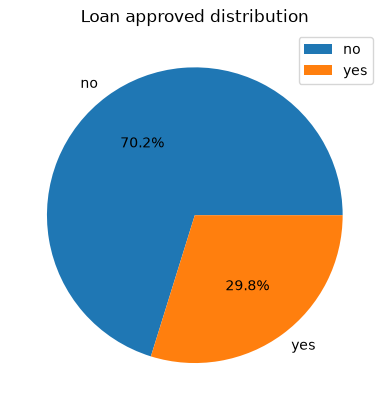

In [100]:
classes_count = df["Loan_Approved"].value_counts()    
plt.pie(classes_count, labels = ["no","yes"],autopct = "%1.1f%%")
plt.title("Loan approved distribution")
plt.legend()

[Text(0, 0, '621'), Text(0, 0, '379')]

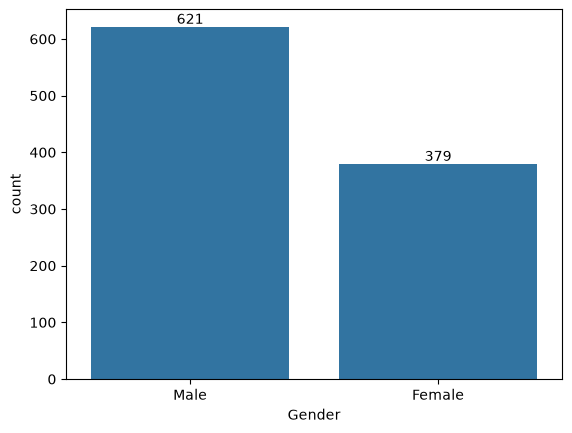

In [101]:
# analyze gender category
gender_cnt = df["Gender"].value_counts()
ax = sns.barplot(gender_cnt)
ax.bar_label(ax.containers[0])

[Text(0, 0, '722'), Text(0, 0, '278')]

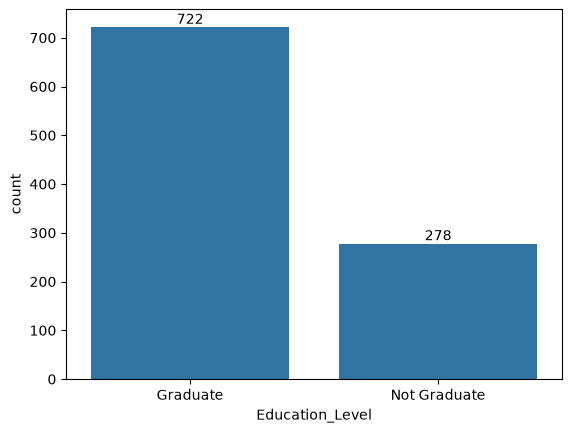

In [102]:
# analyze Education level
Education_cnt = df["Education_Level"].value_counts()
ax = sns.barplot(Education_cnt)
ax.bar_label(ax.containers[0])

[Text(0, 0, '422'),
 Text(0, 0, '202'),
 Text(0, 0, '144'),
 Text(0, 0, '135'),
 Text(0, 0, '97')]

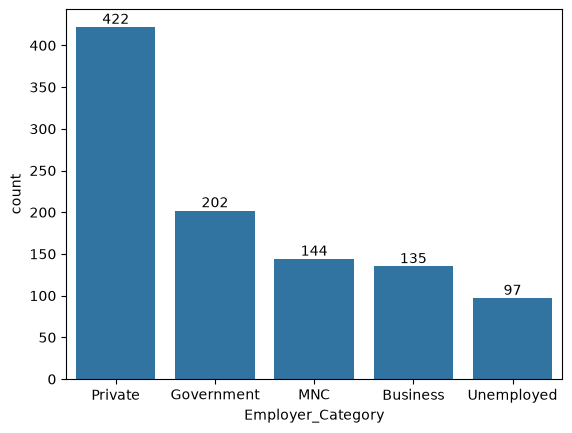

In [103]:
# analyze Employer category
Employer_cnt = df["Employer_Category"].value_counts()
ax = sns.barplot(Employer_cnt)
ax.bar_label(ax.containers[0])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

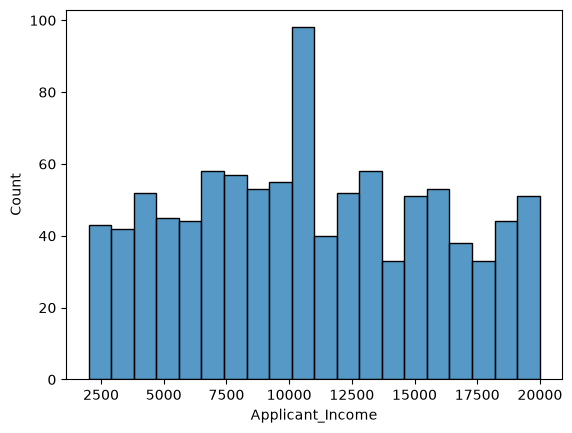

In [104]:
# analyze income
sns.histplot(
    data = df,
    x = "Applicant_Income",
    bins = 20
    
)

<Axes: xlabel='Coapplicant_Income', ylabel='Count'>

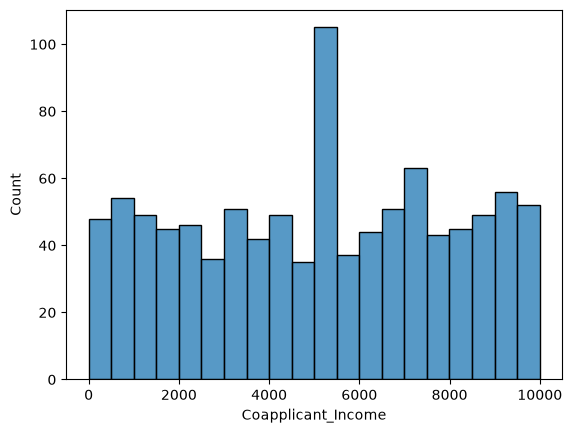

In [105]:
# analyze income
sns.histplot(
    data = df,
    x = "Coapplicant_Income",
    bins = 20
    
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

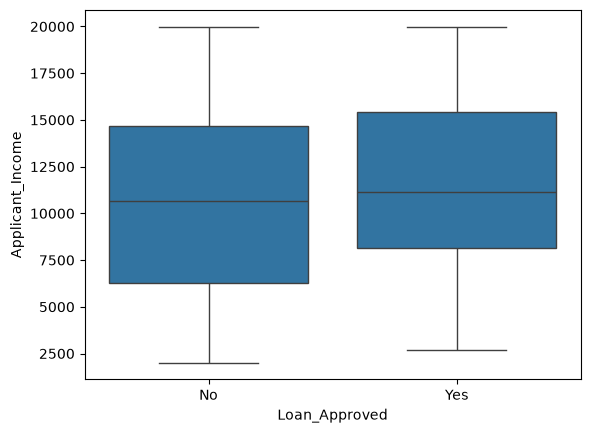

In [106]:
#outliers- Box plot
sns.boxplot(
    data = df,
    x = "Loan_Approved",
    y = "Applicant_Income"
    
)

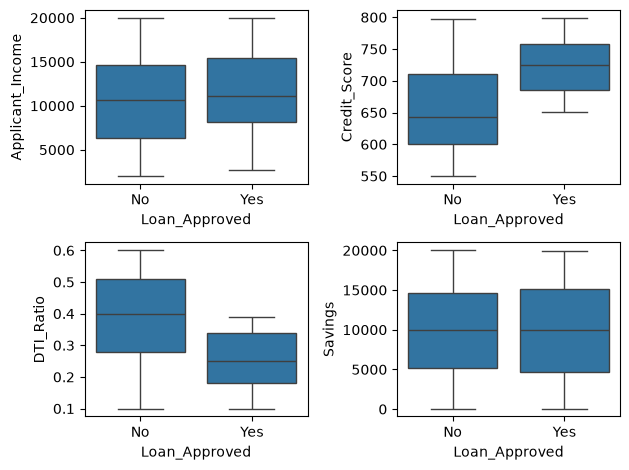

In [107]:
fig ,axes = plt.subplots(2,2)
sns.boxplot(ax = axes[0,0], data = df, x = "Loan_Approved",y = "Applicant_Income")
sns.boxplot(ax = axes[0,1], data = df, x = "Loan_Approved",y = "Credit_Score")
sns.boxplot(ax = axes[1,0], data = df, x = "Loan_Approved",y = "DTI_Ratio")
sns.boxplot(ax = axes[1,1], data = df, x = "Loan_Approved",y = "Savings")
plt.tight_layout()

<Axes: xlabel='Credit_Score', ylabel='Count'>

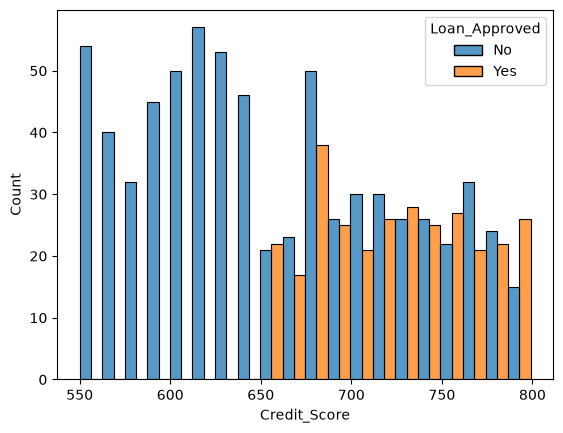

In [108]:
# credit score with Loan approved
sns.histplot(
    data = df, 
    x = "Credit_Score",
    hue = "Loan_Approved",
    bins = 20,
    multiple = "dodge"
    
)

In [109]:
# Remove the Applicant Id
df = df.drop("Applicant_ID", axis = 1)

In [110]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


# ENCODING

In [111]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_Income    1000 non-null   float64
 1   Coapplicant_Income  1000 non-null   float64
 2   Employment_Status   1000 non-null   str    
 3   Age                 1000 non-null   float64
 4   Marital_Status      1000 non-null   str    
 5   Dependents          1000 non-null   float64
 6   Credit_Score        1000 non-null   float64
 7   Existing_Loans      1000 non-null   float64
 8   DTI_Ratio           1000 non-null   float64
 9   Savings             1000 non-null   float64
 10  Collateral_Value    1000 non-null   float64
 11  Loan_Amount         1000 non-null   float64
 12  Loan_Term           1000 non-null   float64
 13  Loan_Purpose        1000 non-null   str    
 14  Property_Area       1000 non-null   str    
 15  Education_Level     1000 non-null   str    
 16  Gender            

In [112]:
col = ["Employment_Status","Marital_Status","Loan_Purpose","Property_Area","Gender","Employer_Category"]


In [113]:
le = LabelEncoder()
df["Education_Level"] = le.fit_transform(df["Education_Level"])
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])

In [114]:
ohe = OneHotEncoder(drop = "first", sparse_output = False, handle_unknown = "ignore")
encoded = ohe.fit_transform(df[col])
encoded_df = pd.DataFrame(encoded, columns = ohe.get_feature_names_out(col), index = df.index)

In [115]:
df = pd.concat([df.drop(columns=col),encoded_df], axis = 1)

In [116]:
df.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


# Correlation Heatmap

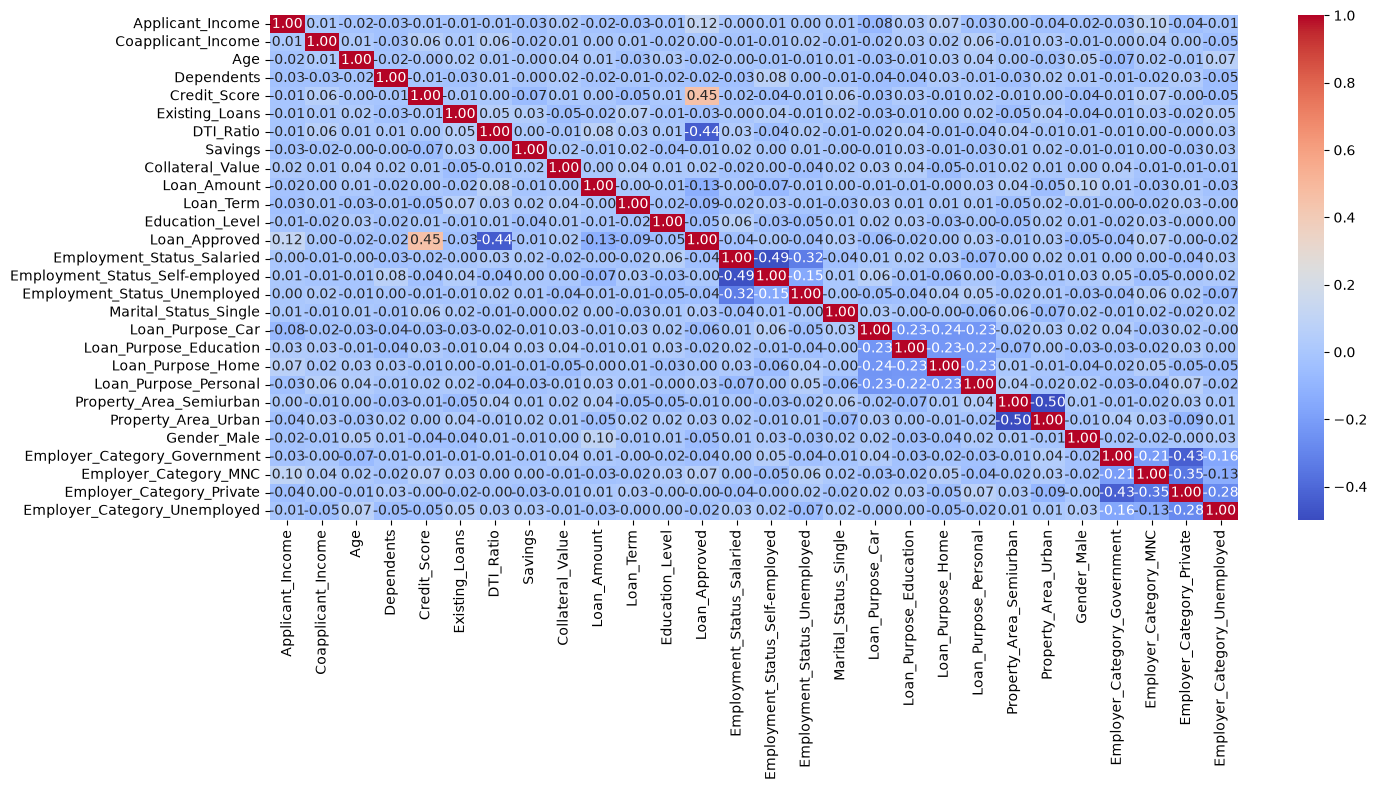

In [117]:
num_cols = df.select_dtypes(include = "number")
corr_matrix = num_cols.corr()

plt.figure(figsize=(15,8))
sns.heatmap(
    corr_matrix,
    annot = True,
    fmt = ".2f",
    cmap = "coolwarm"
    
)
plt.tight_layout()

In [118]:
num_cols.corr()["Loan_Approved"].sort_values(ascending = False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                 

Train-Test-Split + Feature Scaling


In [141]:
X = df.drop("Loan_Approved", axis = 1)
y = df["Loan_Approved"]

#train test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [142]:
#Scaling 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


 # Train and Evaluate

In [148]:
#Logistic Regression
lg_model = LogisticRegression(max_iter = 1000)
lg_model.fit(X_train_scaled,y_train)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [149]:
y_predict= lg_model.predict(X_test_scaled)

print("accuracy: ", accuracy_score(y_test, y_predict))
print("precision: ", precision_score(y_test, y_predict))
print("Recall: ", recall_score(y_test, y_predict),)
print("F1_score: ", f1_score(y_test, y_predict),)

accuracy:  0.865
precision:  0.7833333333333333
Recall:  0.7704918032786885
F1_score:  0.7768595041322314


In [150]:
#Naive Bayes Model
nb_model =  GaussianNB()
nb_model.fit(X_train_scaled,y_train)

y_pred = nb_model.predict(X_test_scaled)

print("accuracy: ", accuracy_score(y_test, y_pred))
print("precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred),)
print("F1_score: ", f1_score(y_test, y_pred),)

accuracy:  0.865
precision:  0.8035714285714286
Recall:  0.7377049180327869
F1_score:  0.7692307692307693


In [146]:
#KNN Model


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

pipeline = Pipeline([
    ('scaler', StandardScaler()), 
    ('knn', KNeighborsClassifier())
])

param_grid = {"knn__n_neighbors": [3, 5, 7, 9]}

classifierCV = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="precision"
)

classifierCV.fit(X_train, y_train)

y_pred = classifierCV.predict(X_test)

print("recall score: ", recall_score(y_test, y_pred))
print("accuracy score: ", accuracy_score(y_test, y_pred))
print("precision score: ", precision_score(y_test, y_pred))

print(classifierCV.best_params_)


recall score:  0.4426229508196721
accuracy score:  0.76
precision score:  0.6585365853658537
{'knn__n_neighbors': 9}


# Best model till now on the basis of precision => Naive Bayes Model

# Feature engineering

In [156]:
df["DTI_Ratio_sq"] = df["DTI_Ratio"]**2
df["Credit_Score_sq"] = df["Credit_Score"]**2


X = df.drop(columns = ["DTI_Ratio","Credit_Score","Loan_Approved"])
y = df["Loan_Approved"]

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
#scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [157]:
#Logistic Regression
lg_model = LogisticRegression(max_iter = 1000)
lg_model.fit(X_train_scaled,y_train)

y_predict= lg_model.predict(X_test_scaled)

print("accuracy: ", accuracy_score(y_test, y_predict))
print("precision: ", precision_score(y_test, y_predict))
print("Recall: ", recall_score(y_test, y_predict),)
print("F1_score: ", f1_score(y_test, y_predict),)
print("CM: ",confusion_matrix(y_test, y_predict),)


accuracy:  0.88
precision:  0.7846153846153846
Recall:  0.8360655737704918
F1_score:  0.8095238095238095
CM:  [[125  14]
 [ 10  51]]


In [158]:
#Naive Bayes Model
nb_model =  GaussianNB()
nb_model.fit(X_train_scaled,y_train)

y_pred = nb_model.predict(X_test_scaled)

print("accuracy: ", accuracy_score(y_test, y_pred))
print("precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred),)
print("F1_score: ", f1_score(y_test, y_pred),)
print("CM: ",confusion_matrix(y_test, y_pred),)

accuracy:  0.86
precision:  0.8113207547169812
Recall:  0.7049180327868853
F1_score:  0.7543859649122807
CM:  [[129  10]
 [ 18  43]]


In [159]:
#KNN Model


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

pipeline = Pipeline([
    ('scaler', StandardScaler()), 
    ('knn', KNeighborsClassifier())
])

param_grid = {"knn__n_neighbors": [3, 5, 7, 9]}

classifierCV = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="precision"
)

classifierCV.fit(X_train, y_train)

y_pred = classifierCV.predict(X_test)

print("recall score: ", recall_score(y_test, y_pred))
print("accuracy score: ", accuracy_score(y_test, y_pred))
print("precision score: ", precision_score(y_test, y_pred))

print(classifierCV.best_params_)

recall score:  0.4918032786885246
accuracy score:  0.775
precision score:  0.6818181818181818
{'knn__n_neighbors': 9}
